# EDA (EXPLORATORY DATA ANALYSIS)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load dataset
df = pd.read_csv('cleaned_master_inventory.csv')

In [3]:
## INVENTORY COST VALUE BY EXPIRY STATUS
status_summary = df.groupby('expiry_status').agg(
    batch_count=('batch_id', 'count'),
    total_stock_units=('current_stock_quantity', 'sum'),
    total_cost_usd=('stock_value_cost_usd', 'sum'),
    total_retail_usd=('stock_value_retail_usd', 'sum')
).reset_index()

In [4]:
status_summary.head()

,expiry_status,batch_count,total_stock_units,total_cost_usd,total_retail_usd
0,Critical (0-30 Days),9,1236,22345.52,39203.44
1,Expired,73,2912,59041.69,95620.51
2,Fresh Stock (90 Days),95,24475,534330.15,897134.45
3,High Risk (31-60 Days),8,883,19392.91,37519.86
4,Moderate Risk (61-90 Days),8,1292,30331.08,46306.31


In [5]:
## IMPENDING WASTE EXPOSURE (<= 90 DAYS)
## Slices the dataset to look only at batches expiring within the next 90 days

risk_categories = df[df['days_to_expiry'] <= 90].groupby('category').agg(
    batches_at_risk=('batch_id', 'count'),
    stock_value_cost=('stock_value_cost_usd', 'sum')
).sort_values('stock_value_cost', ascending=False).reset_index()

In [6]:
risk_categories

,category,batches_at_risk,stock_value_cost
0,Cardiovascular,13,26804.78
1,Gastrointestinal,16,25670.56
2,Vitamins & Supplements,12,18584.16
3,Antibiotics,11,14078.82
4,Antidiabetics,10,13620.98
5,Respiratory,10,12882.59
6,Pain Relief & Anti-inflammatory,14,12558.27
7,Dermatology & Topical,12,6911.04


In [8]:
### TOP BATCHES IN THE 'WASTE DANGER ZONE'

danger_zone_batches = df[df['waste_risk_flag'] == True][[
    'batch_id', 'product_name', 'category', 'current_stock_quantity',
    'days_to_expiry', 'avg_daily_sales', 'days_of_stock_remaining', 'stock_value_cost_usd'
]].sort_values('stock_value_cost_usd', ascending=False)

print(f"Total Batches Identified: {len(danger_zone_batches)}")
print(f"Total Financial Value at Risk: ${danger_zone_batches['stock_value_cost_usd'].sum():,.2f}")
display(danger_zone_batches.head(10))

Total Batches Identified: 9
Total Financial Value at Risk: $33,324.14


,batch_id,product_name,category,current_stock_quantity,days_to_expiry,avg_daily_sales,days_of_stock_remaining,stock_value_cost_usd
148,BAT-2025-249,Vitamin C 500mg,Vitamins & Supplements,189,44,1.988889,95.027933,7786.80
45,BAT-2025-146,Atorvastatin 20mg,Cardiovascular,245,14,2.733333,89.634146,6519.45
42,BAT-2025-143,Aspirin 81mg,Pain Relief & Anti-inflammatory,250,36,2.166667,115.384615,6377.50
156,BAT-2025-257,Calcium + D3,Vitamins & Supplements,231,26,5.522222,41.830986,5446.98
127,BAT-2025-228,Pantoprazole 40mg,Gastrointestinal,136,13,5.222222,26.042553,3334.72
51,BAT-2025-152,Amlodipine 5mg,Cardiovascular,188,23,2.166667,86.769231,2145.08
70,BAT-2025-171,Metformin 500mg,Antidiabetics,63,3,5.044444,12.488987,765.45
13,BAT-2025-114,Cephalexin 500mg,Antibiotics,241,29,1.955556,123.238636,674.80
174,BAT-2025-275,Hydrocortisone Cream 1%,Dermatology & Topical,68,53,1.233333,55.135135,273.36


# Charts 

In [10]:
# Set global visual style
sns.set_theme(style="white")
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "font.size": 10})

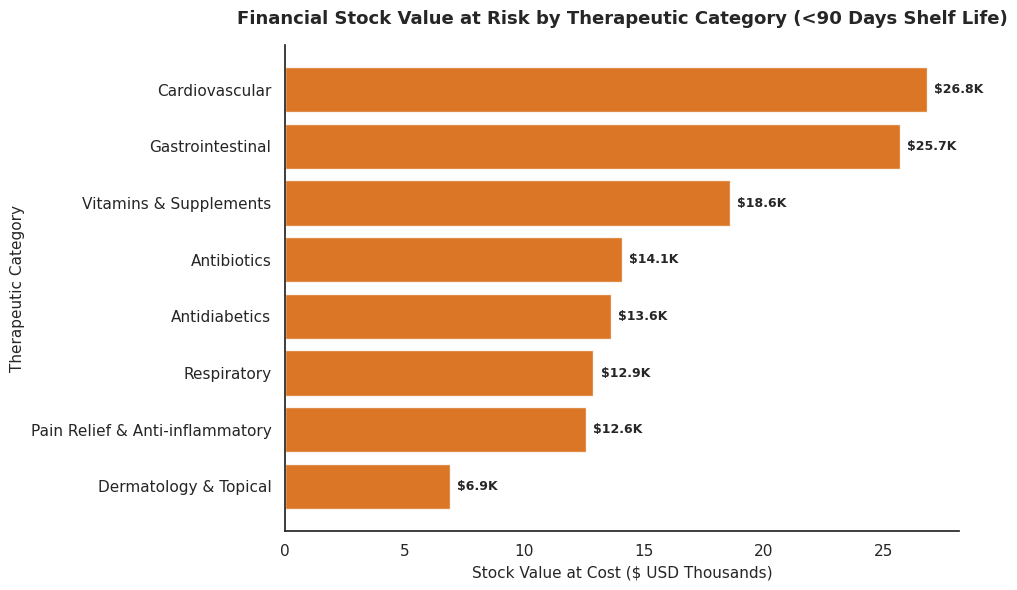

In [12]:
# --- Chart 1: Category Financial Exposure Bar Chart ---
fig, ax = plt.subplots(figsize=(10, 6))

cat_risk = (
    df[df['days_to_expiry'] <= 90]
    .groupby('category')['stock_value_cost_usd']
    .sum()
    .sort_values(ascending=True)
    / 1000.0
)

bars = ax.barh(cat_risk.index, cat_risk.values, color='#D55E00', alpha=0.85)

ax.set_title(
    'Financial Stock Value at Risk by Therapeutic Category (<90 Days Shelf'
    ' Life)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.set_xlabel('Stock Value at Cost ($ USD Thousands)', fontsize=11)
ax.set_ylabel('Therapeutic Category', fontsize=11)

for bar in bars:
  width = bar.get_width()
  ax.text(
      width + 0.3,
      bar.get_y() + bar.get_height() / 2,
      f'${width:.1f}K',
      va='center',
      fontsize=9,
      fontweight='bold',
  )

sns.despine()
plt.tight_layout()
plt.show()

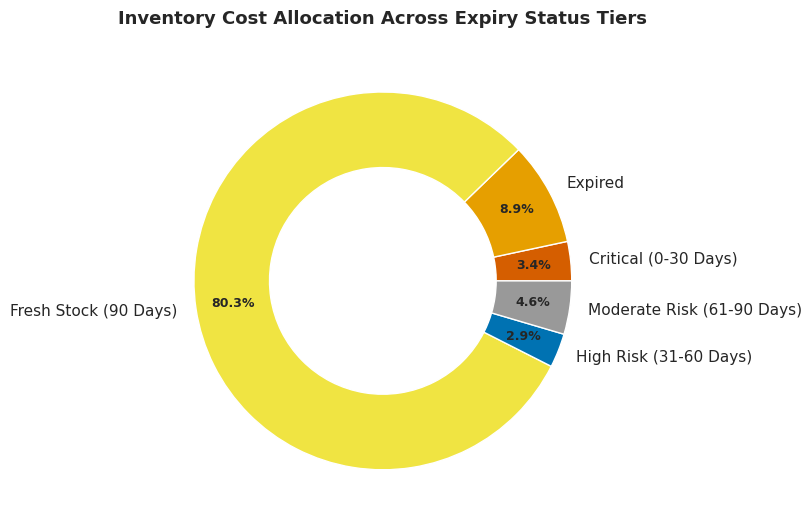

In [14]:
#  Chart 2: Inventory Status Allocation Donut Chart 
fig, ax = plt.subplots(figsize=(8, 8))

status_costs = df.groupby('expiry_status')['stock_value_cost_usd'].sum()
colors = ['#D55E00', '#E69F00', '#F0E442', '#0072B2', '#999999']

wedges, texts, autotexts = ax.pie(
    status_costs,
    labels=status_costs.index,
    autopct='%1.1f%%',
    pctdistance=0.8,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white'),
)

plt.setp(autotexts, size=9, weight='bold')
ax.set_title(
    'Inventory Cost Allocation Across Expiry Status Tiers',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.tight_layout()
plt.show()

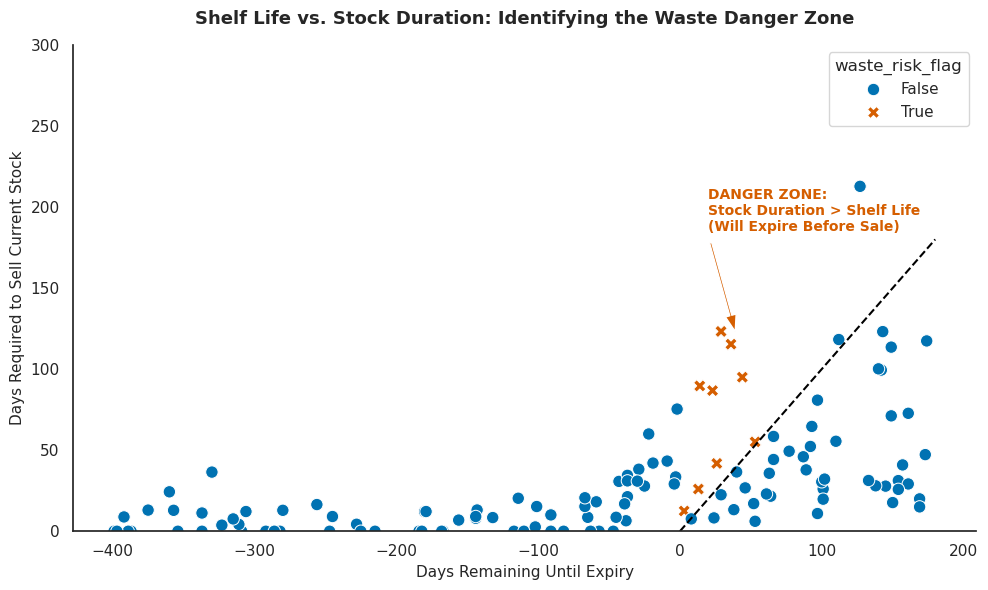

In [19]:
# --- Chart 3: Sales Velocity vs Shelf Life Scatter Plot (Risk Danger Zone) ---
fig, ax = plt.subplots(figsize=(10, 6))

plot_data = df[df['days_to_expiry'] <= 180].copy()

sns.scatterplot(
    data=plot_data,
    x='days_to_expiry',
    y='days_of_stock_remaining',
    hue='waste_risk_flag',
    palette={True: '#D55E00', False: '#0072B2'},
    style='waste_risk_flag',
    s=80,
    ax=ax,
)

# Parity reference line (Days Remaining = Days to Expiry)
ax.plot(
    [0, 180],
    [0, 180],
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Sales Velocity Parity Line',
)

ax.set_title(
    'Shelf Life vs. Stock Duration: Identifying the Waste Danger Zone',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.set_xlabel('Days Remaining Until Expiry', fontsize=11)
ax.set_ylabel('Days Required to Sell Current Stock', fontsize=11)
ax.set_ylim(0, 300)

ax.annotate(
    (
        'DANGER ZONE:\nStock Duration > Shelf Life\n(Will Expire Before'
        ' Sale)'
    ),
    xy=(40, 120),
    xytext=(20, 185),
    arrowprops=dict(
        facecolor='#D55E00', shrink=0.05, width=1.5, headwidth=8
    ),
    fontsize=10,
    fontweight='bold',
    color='#D55E00',
)

sns.despine()
plt.tight_layout()
plt.show()

<Figure size 3000x1800 with 0 Axes>

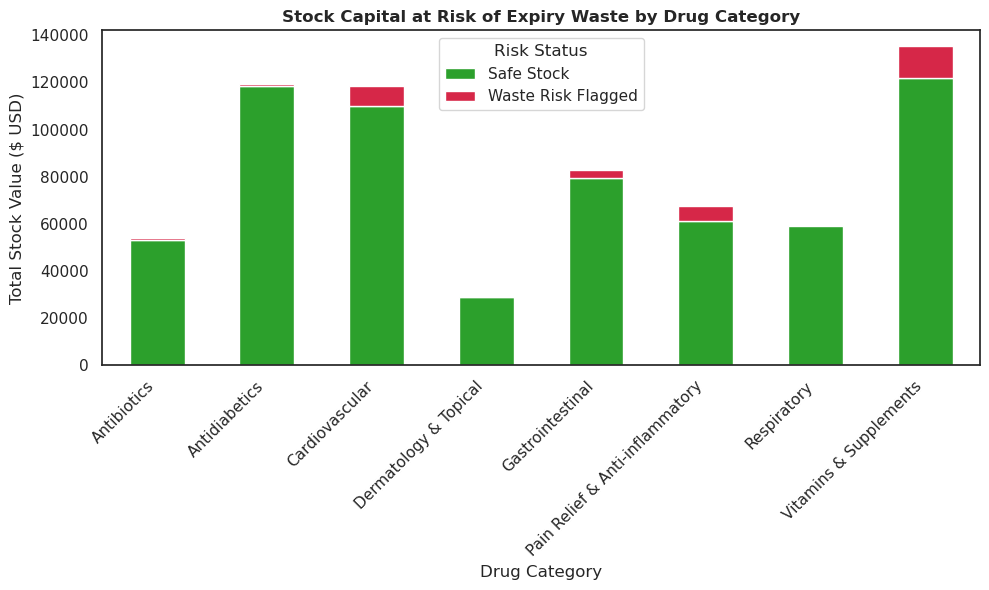

In [24]:
# Waste Risk Exposure by Drug Category 
plt.figure(figsize=(10, 6), dpi=300)
cat_risk = df.groupby(['category', 'waste_risk_flag'])['stock_value_cost_usd'].sum().unstack(fill_value=0)

cat_risk.plot(kind='bar', stacked=True, color=['#2ca02c', '#d62748'], figsize=(10, 6))
plt.title('Stock Capital at Risk of Expiry Waste by Drug Category', fontsize=12, fontweight='bold')
plt.xlabel('Drug Category')
plt.ylabel('Total Stock Value ($ USD)')
plt.legend(['Safe Stock', 'Waste Risk Flagged'], title='Risk Status')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('chart2_waste_risk_by_category.png')
plt.show()

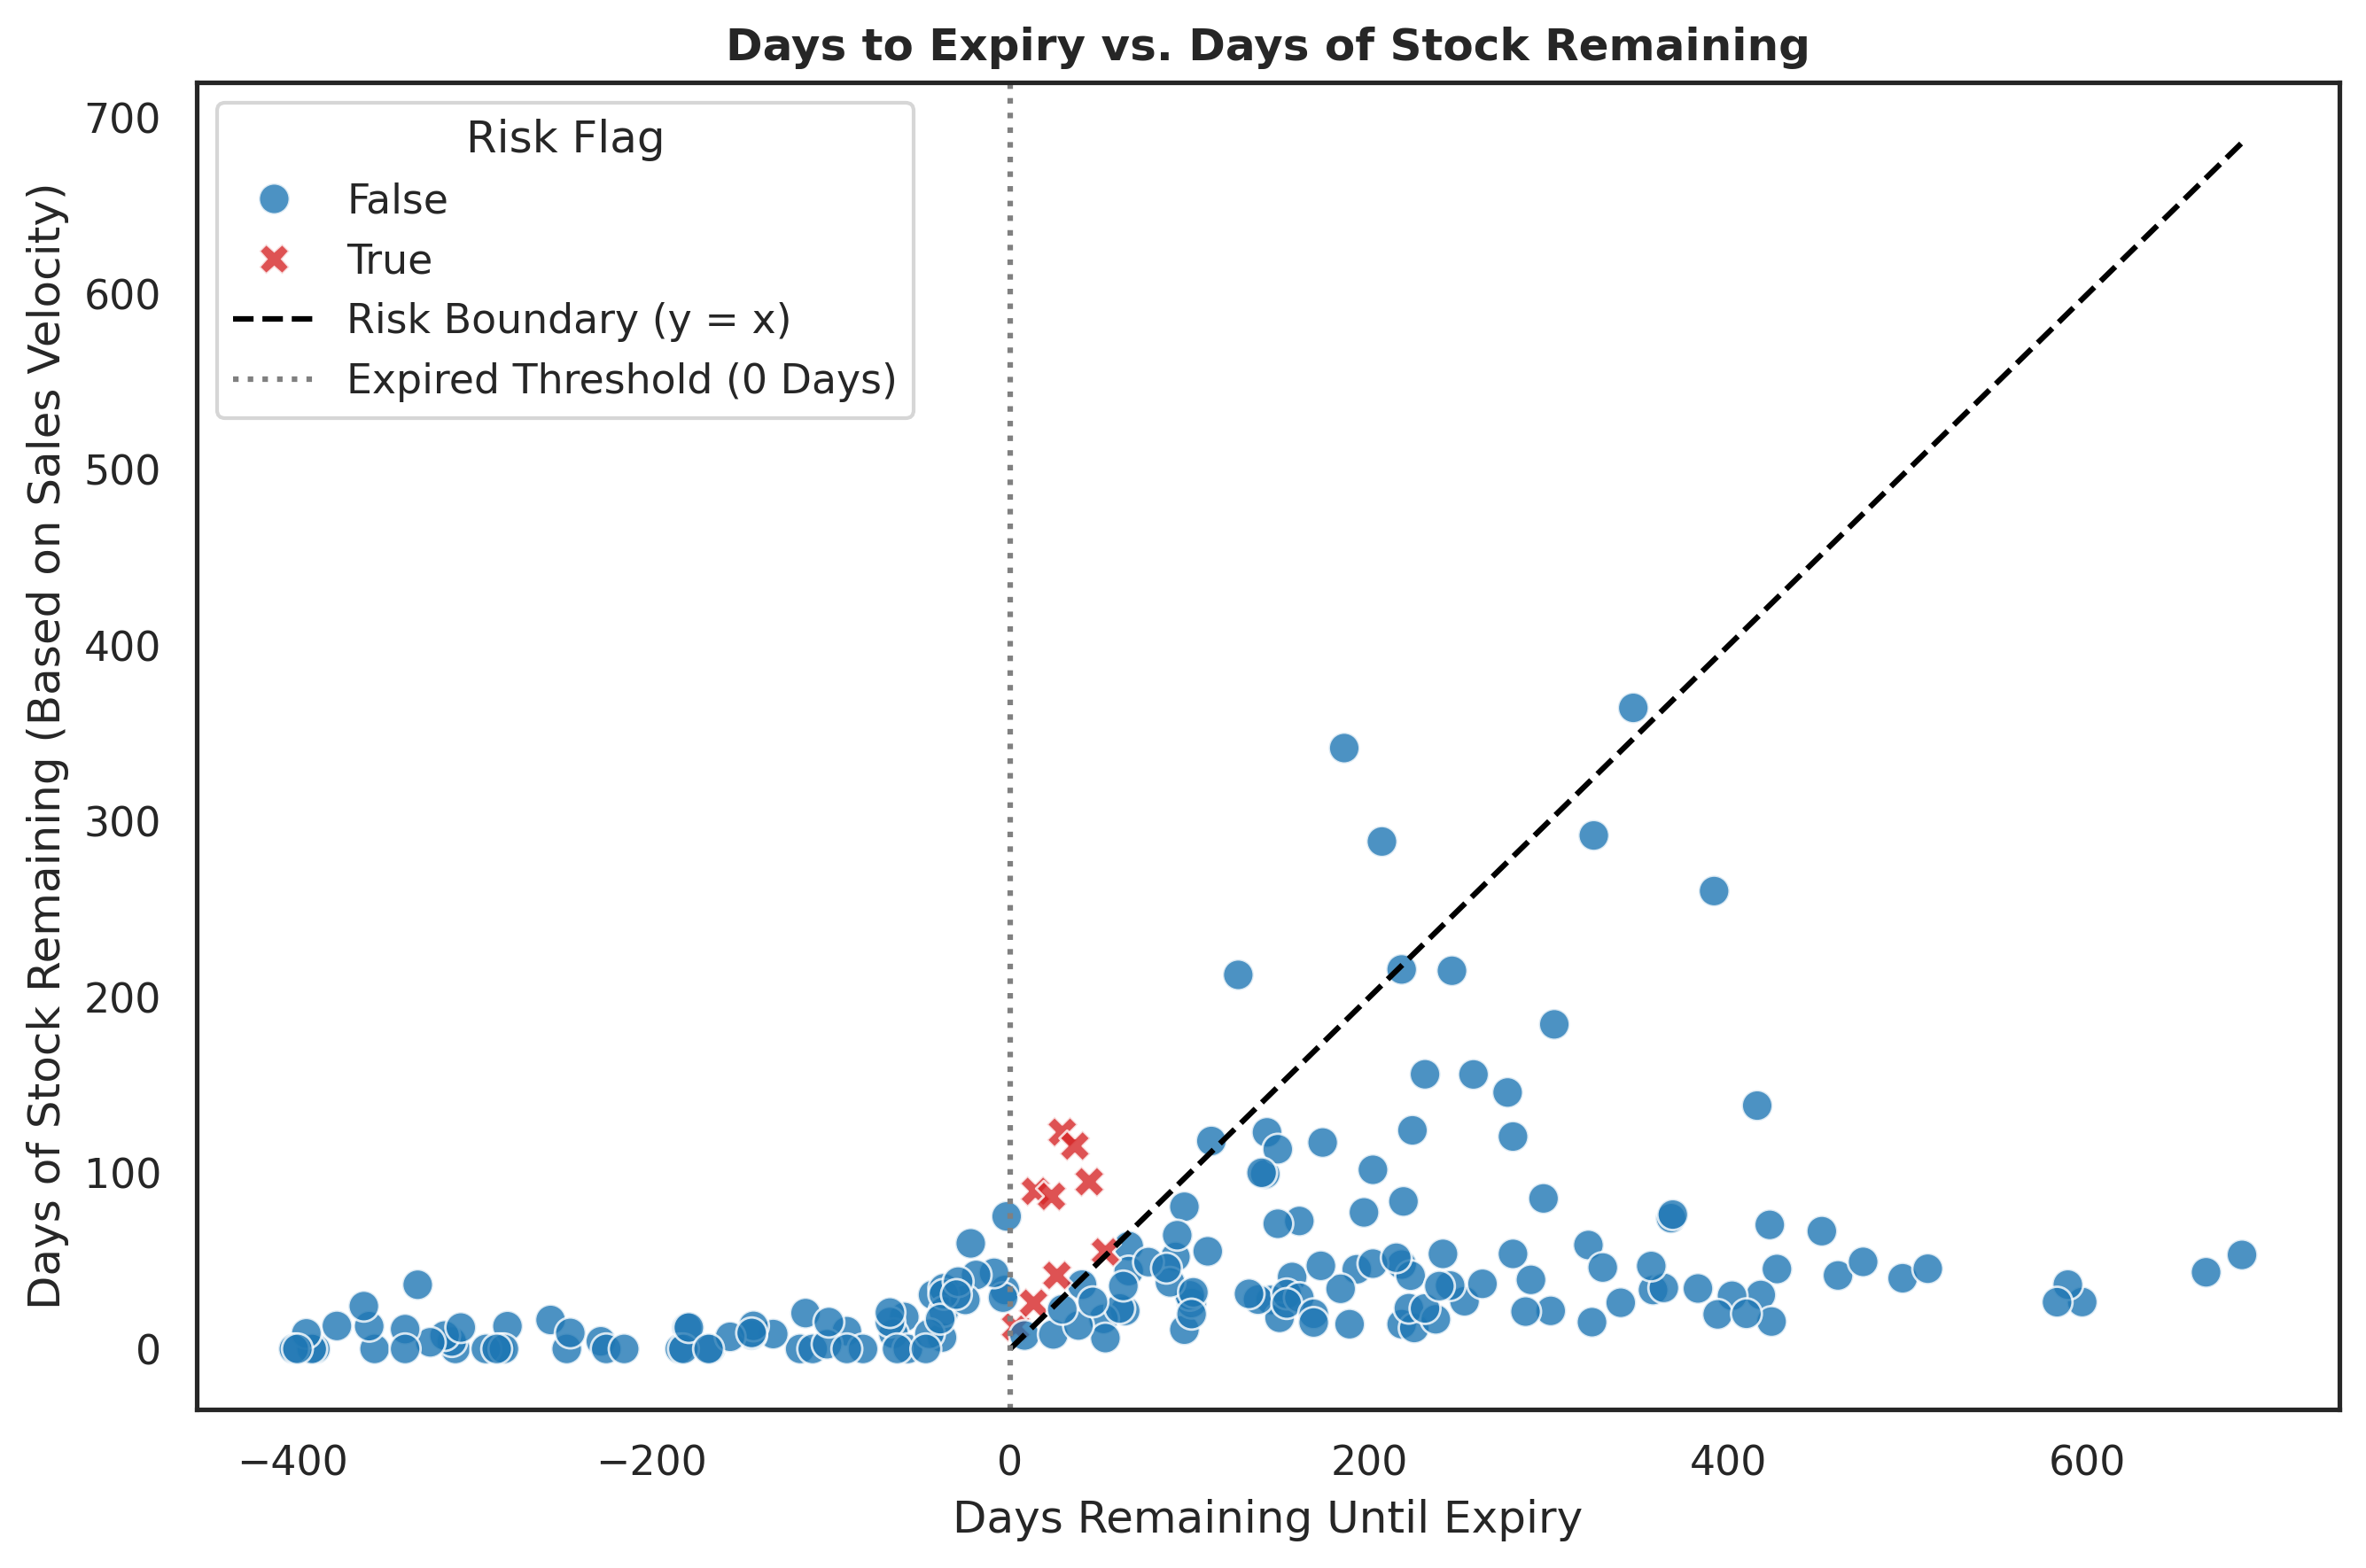

In [25]:
# Sales Velocity vs. Shelf-Life Matrix 
plt.figure(figsize=(9, 6),dpi=300)

# Filter out non-moving dummy stock values (9999 days) for clean plotting
scatter_data = df[df['days_of_stock_remaining'] < 1000].copy()

sns.scatterplot(
    data=scatter_data, 
    x='days_to_expiry', 
    y='days_of_stock_remaining', 
    hue='waste_risk_flag', 
    style='waste_risk_flag',
    palette={False: '#1f77b4', True: '#d62728'},
    s=70,
    alpha=0.8
)

# Plot Risk Boundary line (y = x)
max_limit = max(scatter_data['days_to_expiry'].max(), scatter_data['days_of_stock_remaining'].max())
plt.plot([0, max_limit], [0, max_limit], color='black', linestyle='--', label='Risk Boundary (y = x)')
plt.axvline(0, color='gray', linestyle=':', label='Expired Threshold (0 Days)')

plt.title('Days to Expiry vs. Days of Stock Remaining', fontsize=12, fontweight='bold')
plt.xlabel('Days Remaining Until Expiry')
plt.ylabel('Days of Stock Remaining (Based on Sales Velocity)')
plt.legend(title='Risk Flag')
plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_2484\298497067.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='storage_type', y='days_to_expiry', palette='Set2')


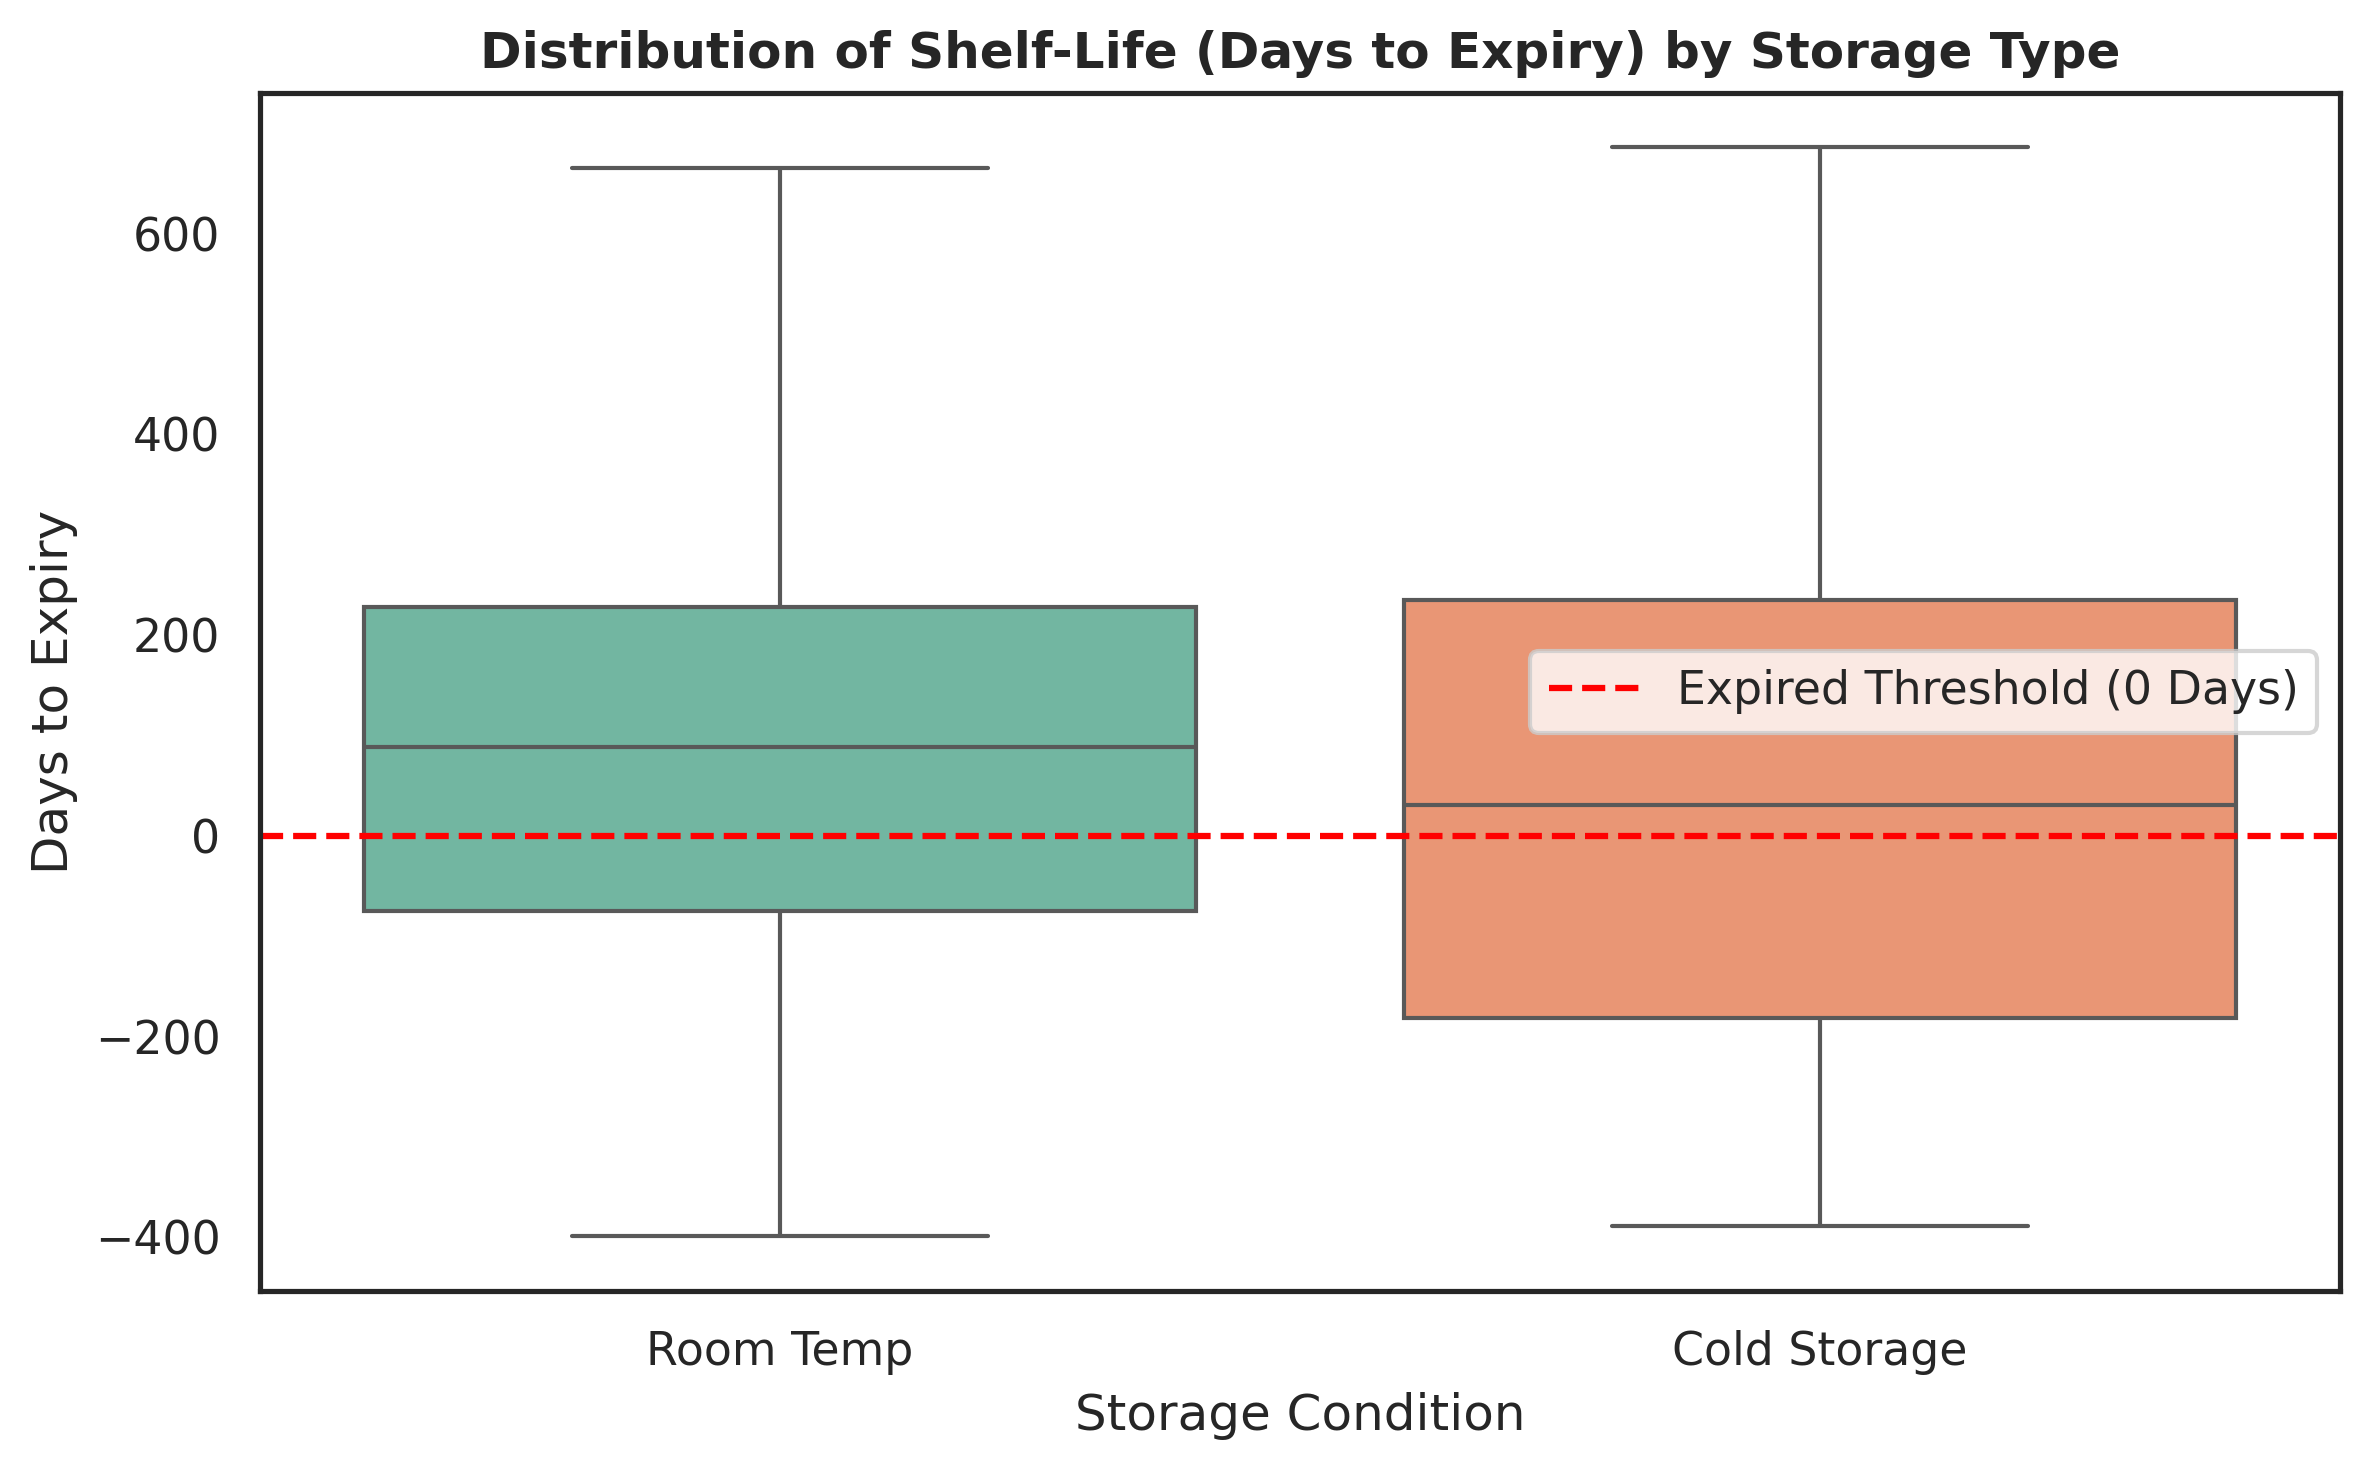

In [26]:
# Shelf-Life Distribution by Storage Condition 
plt.figure(figsize=(8, 5), dpi=300)
sns.boxplot(data=df, x='storage_type', y='days_to_expiry', palette='Set2')
plt.axhline(0, color='red', linestyle='--', label='Expired Threshold (0 Days)')
plt.title('Distribution of Shelf-Life (Days to Expiry) by Storage Type', fontsize=12, fontweight='bold')
plt.xlabel('Storage Condition')
plt.ylabel('Days to Expiry')
plt.legend()
plt.tight_layout()
plt.show()

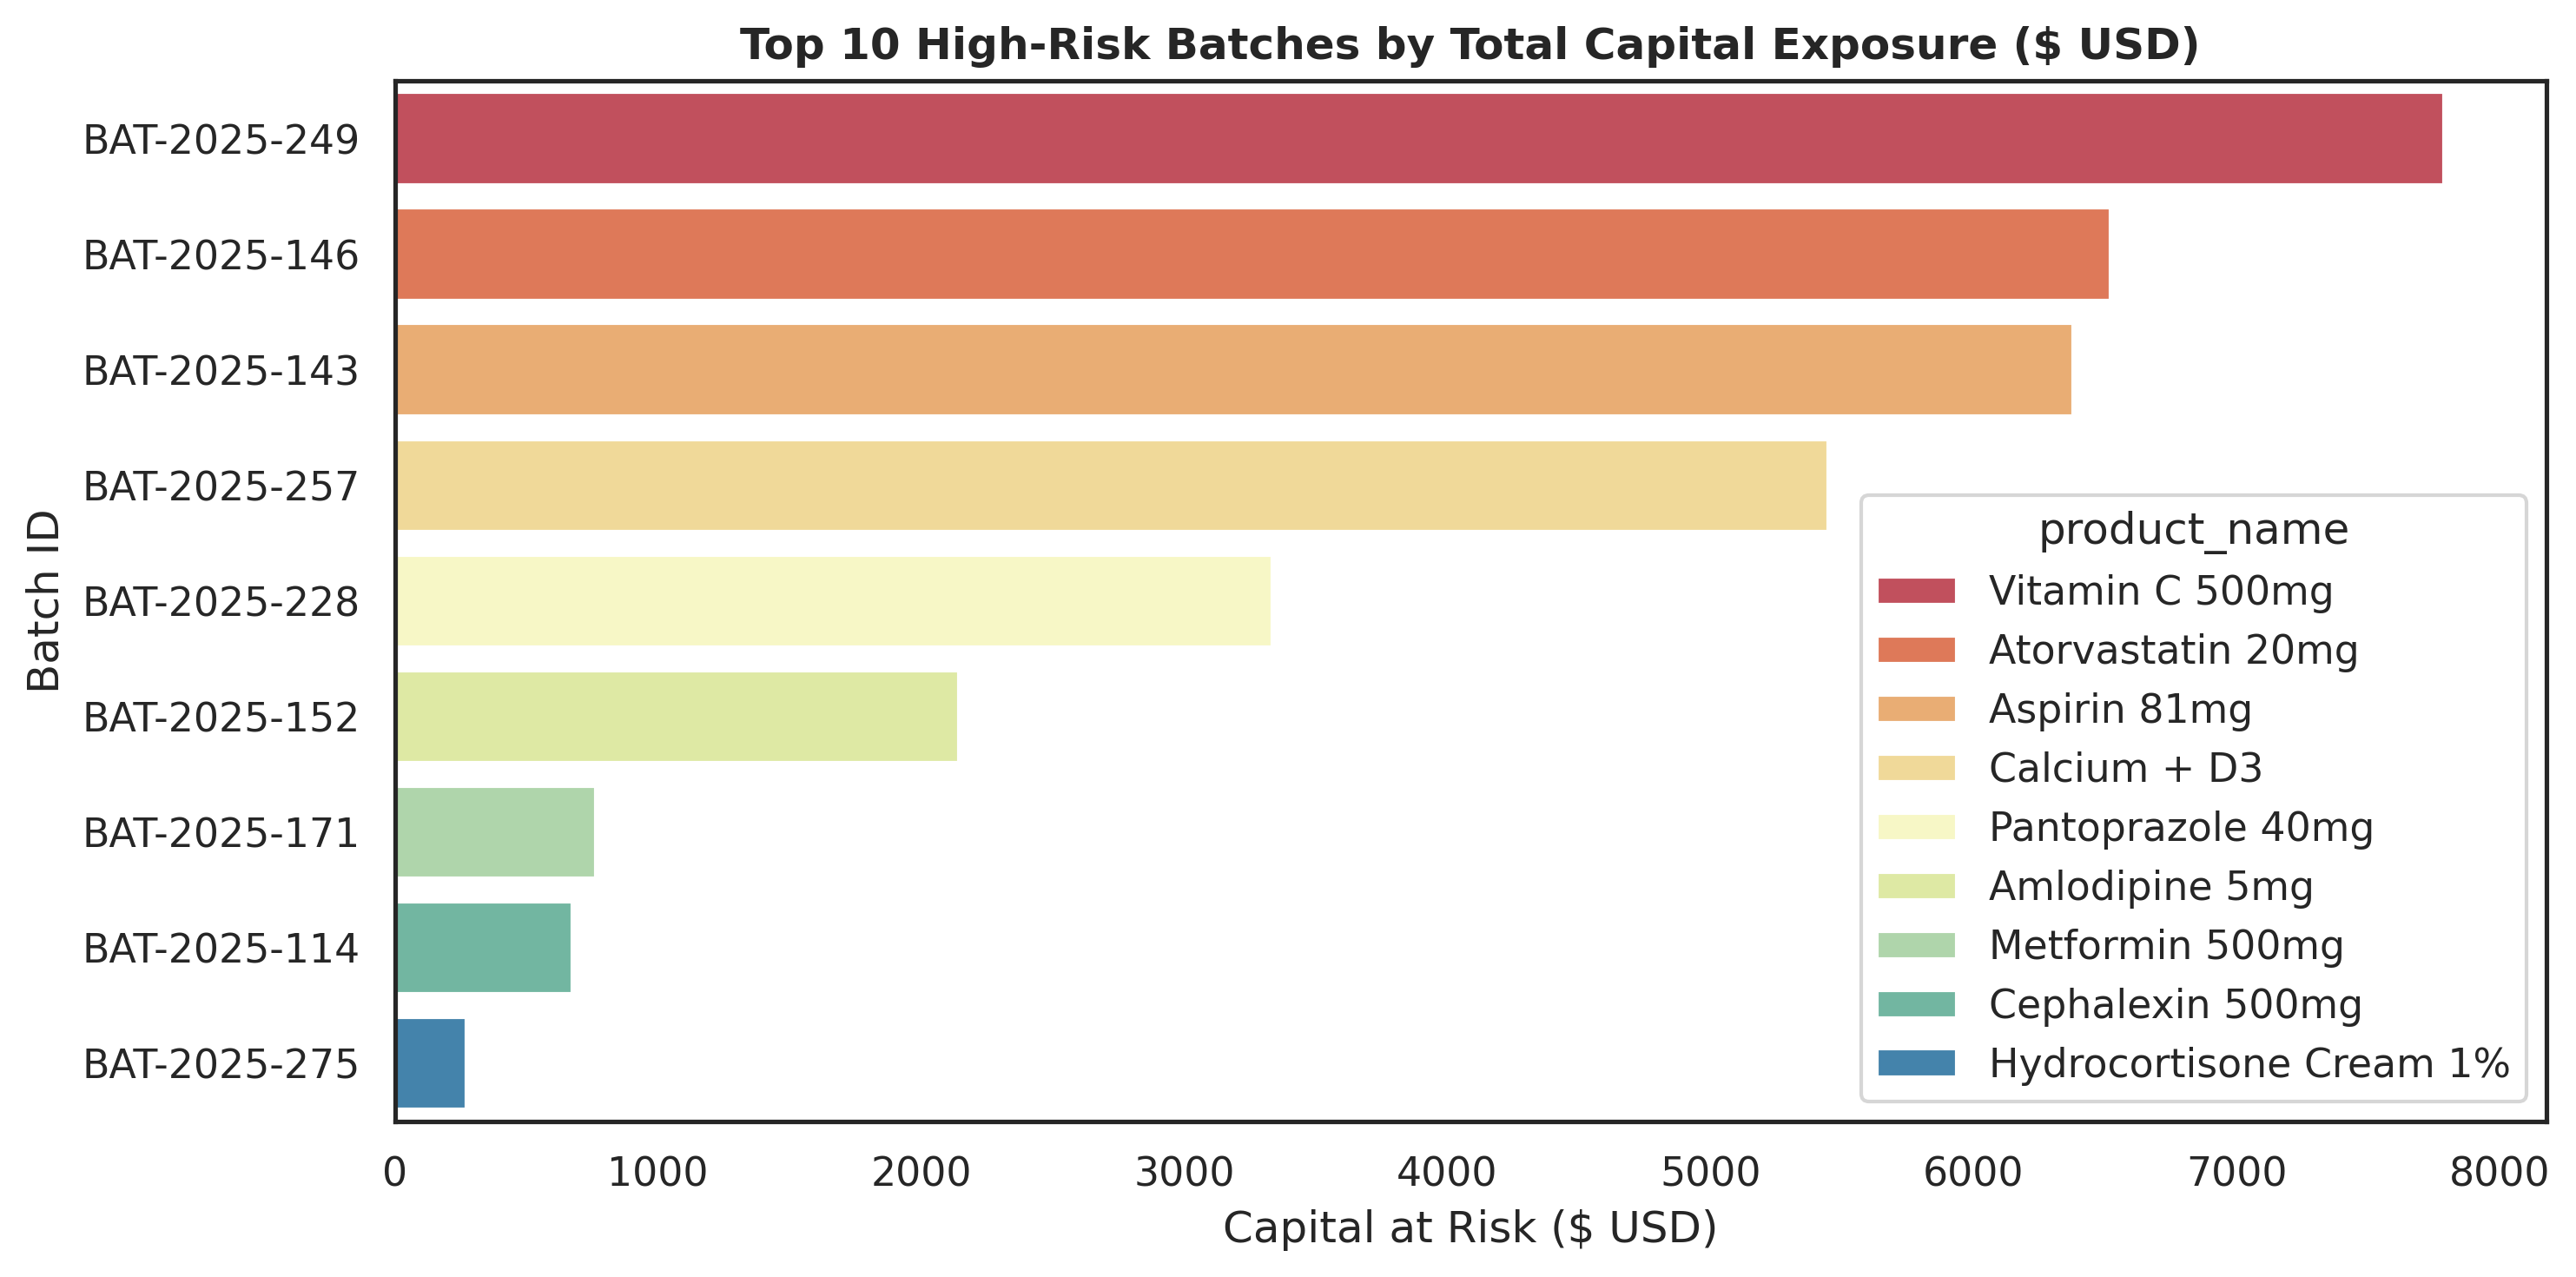

In [27]:
#  Top 10 High-Risk Batches by Dollar Exposure 
plt.figure(figsize=(10, 5), dpi=300)

top_risk_batches = df[df['waste_risk_flag'] == True].sort_values(
    by='stock_value_cost_usd', ascending=False
).head(10)

# Fallback if no batches flagged True
if top_risk_batches.empty:
    top_risk_batches = df.sort_values(by='days_to_expiry', ascending=True).head(10)

sns.barplot(
    data=top_risk_batches, 
    y='batch_id', 
    x='stock_value_cost_usd', 
    hue='product_name', 
    dodge=False, 
    palette='Spectral'
)
plt.title('Top 10 High-Risk Batches by Total Capital Exposure ($ USD)', fontsize=12, fontweight='bold')
plt.xlabel('Capital at Risk ($ USD)')
plt.ylabel('Batch ID')
plt.tight_layout()
plt.show()

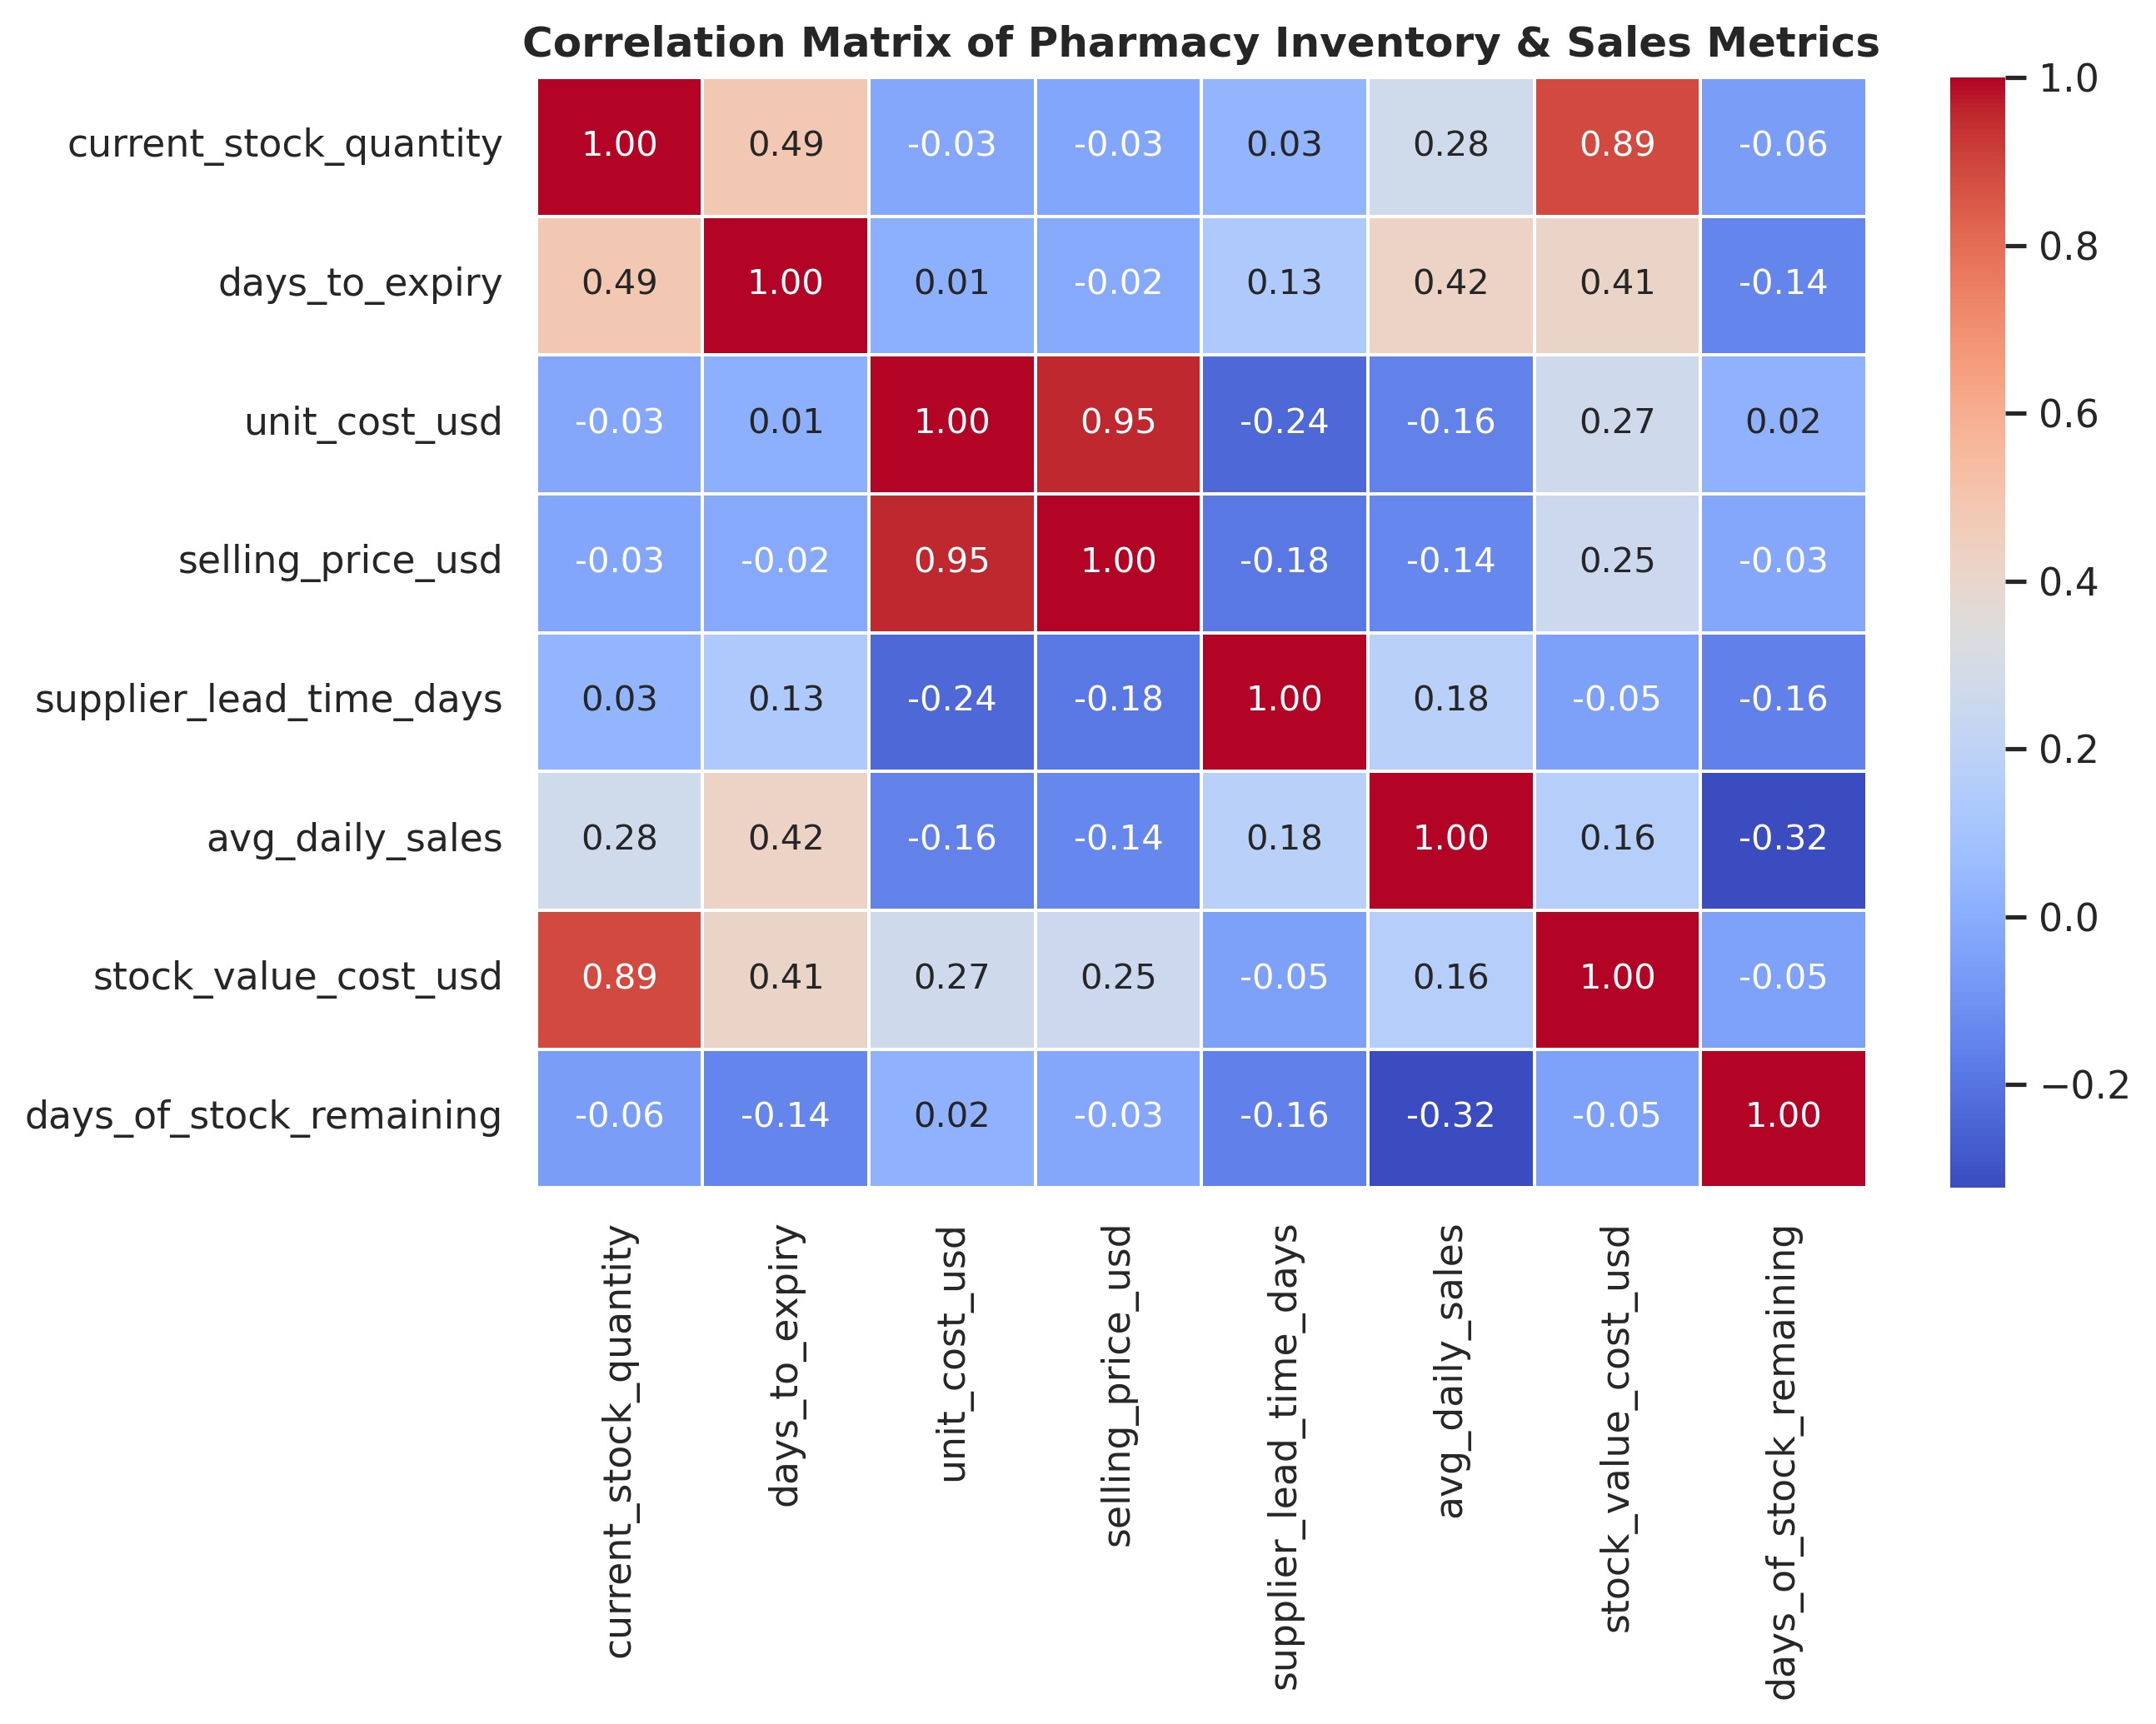

In [28]:
# Operational Features Correlation Heatmap 
plt.figure(figsize=(9, 7), dpi=300)

num_cols = [
    'current_stock_quantity', 'days_to_expiry', 'unit_cost_usd', 
    'selling_price_usd', 'supplier_lead_time_days', 'avg_daily_sales', 
    'stock_value_cost_usd', 'days_of_stock_remaining'
]

corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Pharmacy Inventory & Sales Metrics', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_7620\3109802677.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=q1, x='expiry_status', y='stock_value_cost_usd', ax=axes[0,0], palette='Reds_r')
C:\Users\USER\AppData\Local\Temp\ipykernel_7620\3109802677.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=q2, y='category', x='stock_value_cost_usd', ax=axes[0,1], palette='Oranges_r')
C:\Users\USER\AppData\Local\Temp\ipykernel_7620\3109802677.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=q3, y='product_name', x='days_of_sto

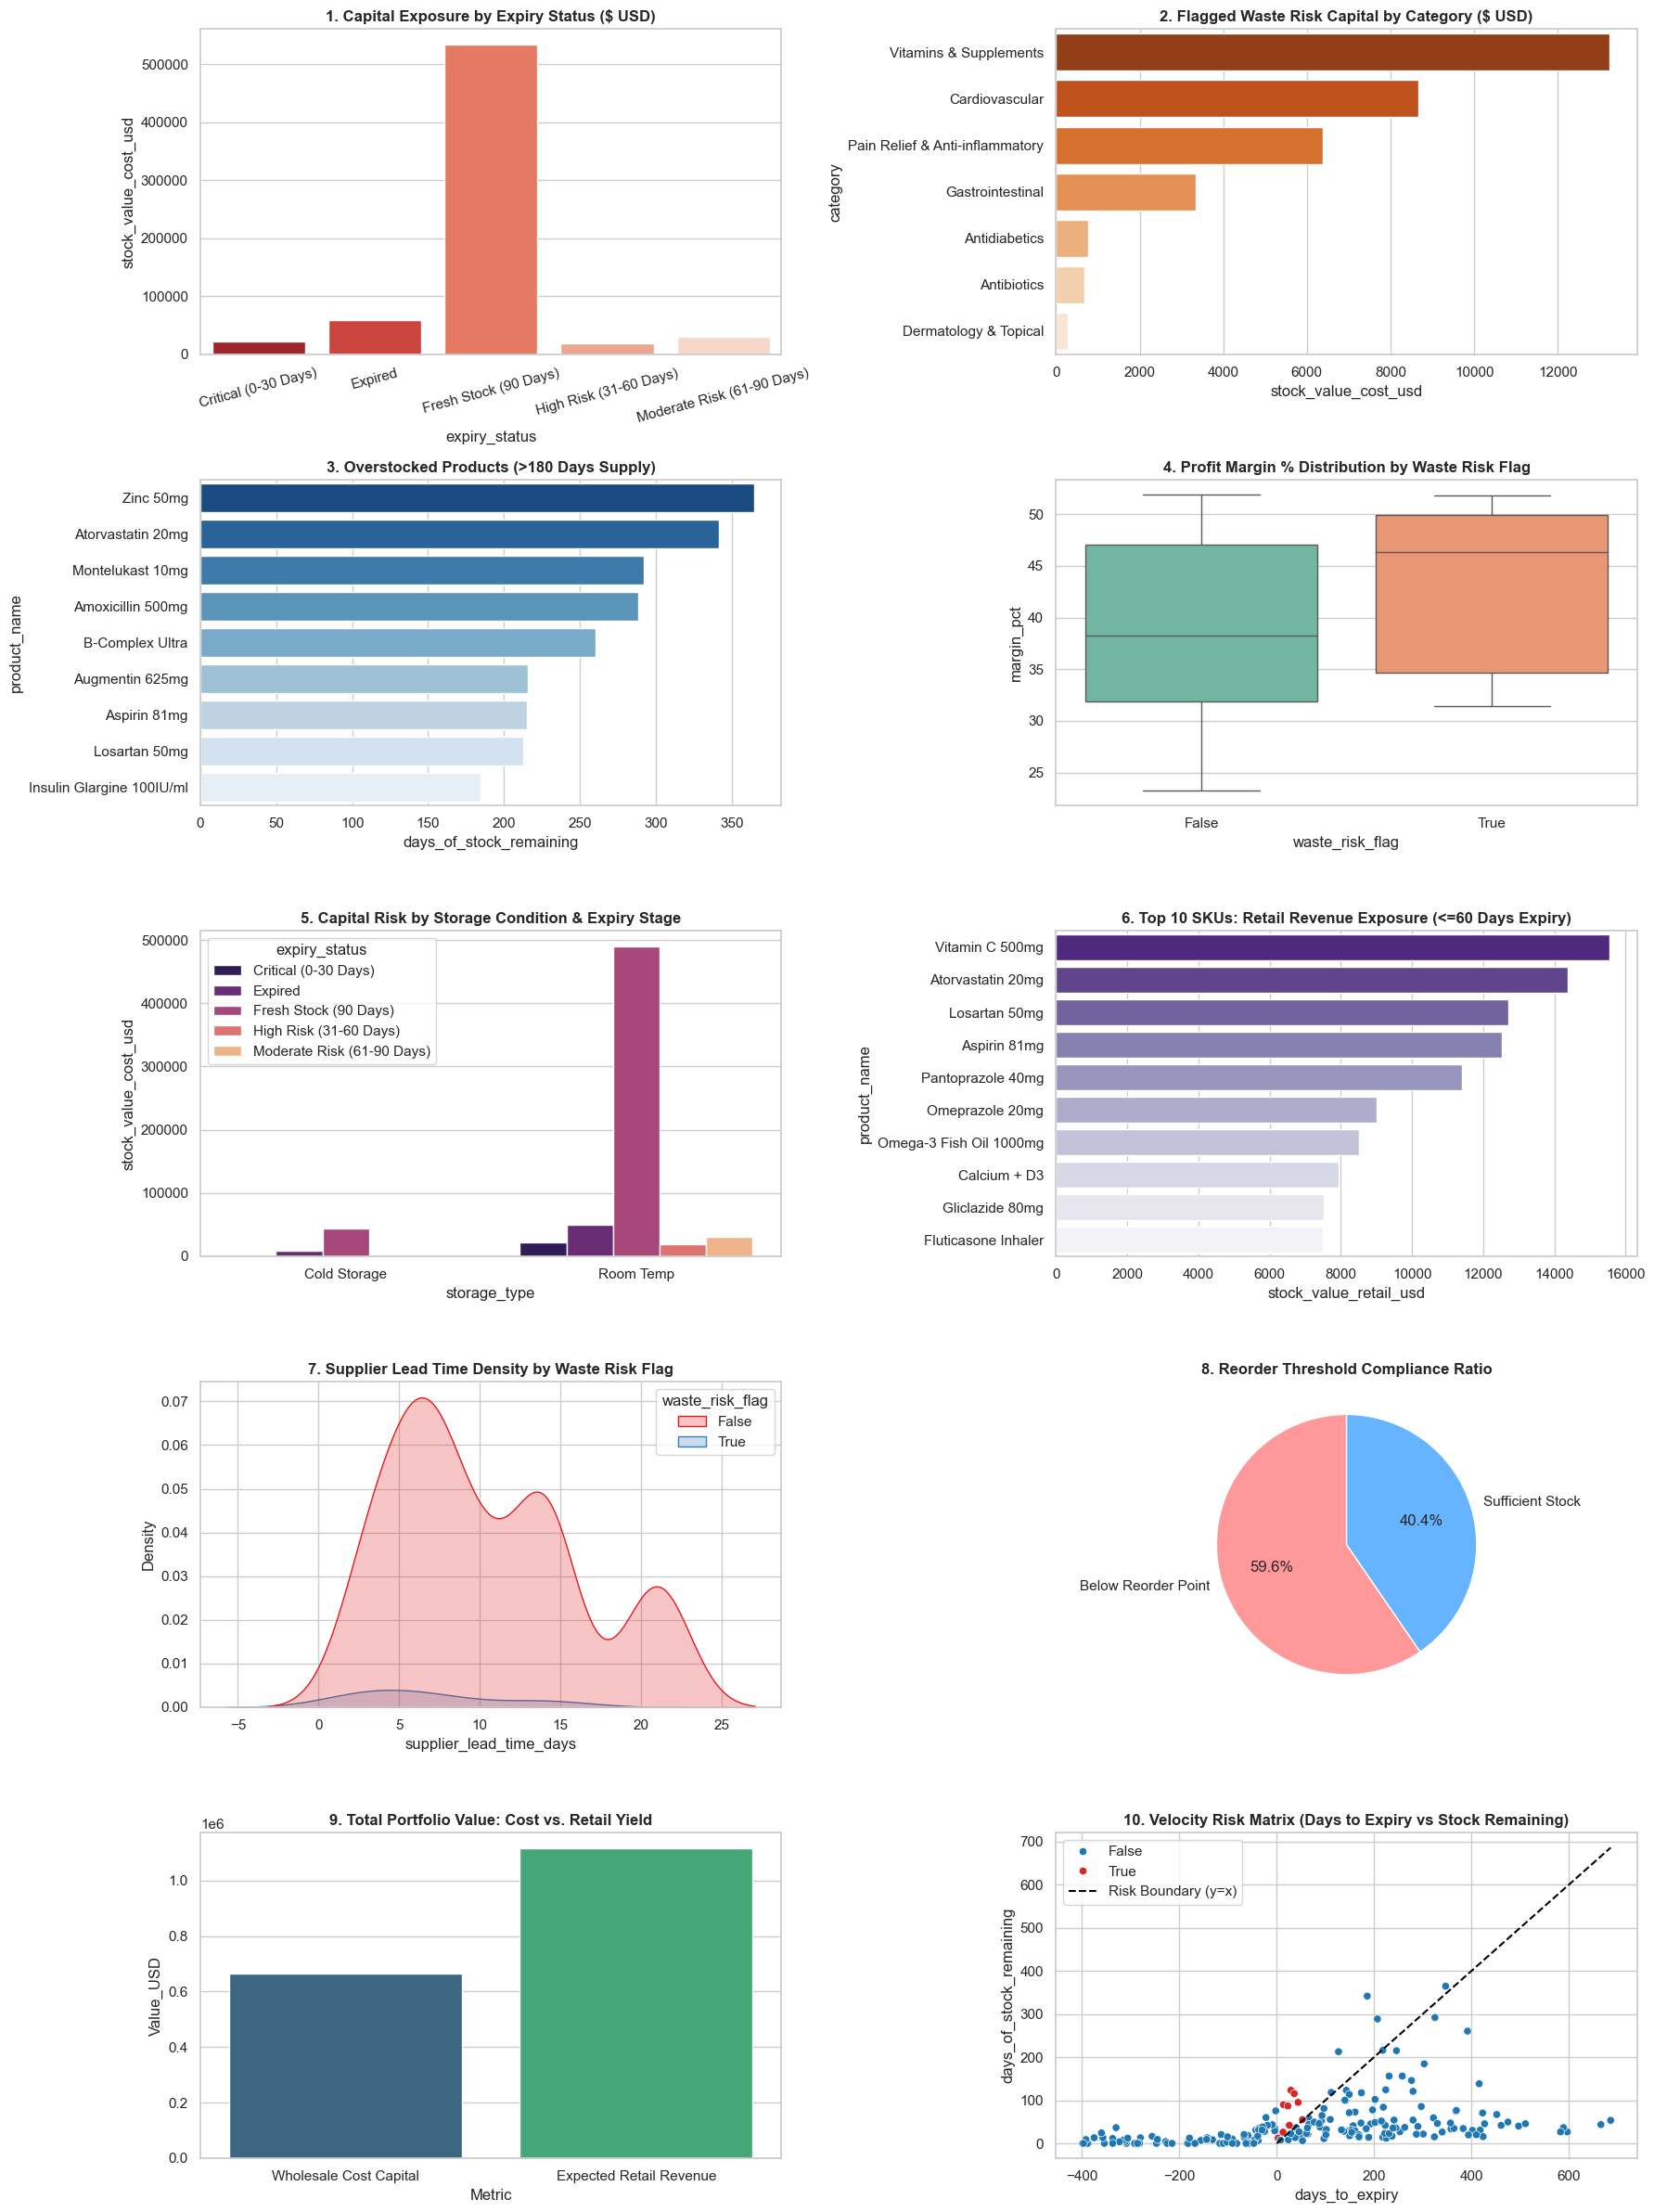

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('cleaned_master_inventory.csv')

# Feature Engineering for Margins
df['profit_margin_usd'] = df['selling_price_usd'] - df['unit_cost_usd']
df['margin_pct'] = (df['profit_margin_usd'] / df['selling_price_usd']) * 100

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(5, 2, figsize=(18, 24))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# 1. Exposure by Expiry Status
q1 = df.groupby('expiry_status')['stock_value_cost_usd'].sum().reset_index()
sns.barplot(data=q1, x='expiry_status', y='stock_value_cost_usd', ax=axes[0,0], palette='Reds_r')
axes[0,0].set_title('1. Capital Exposure by Expiry Status ($ USD)', fontweight='bold')
axes[0,0].tick_params(axis='x', rotation=15)

# 2. Waste Risk by Category
q2 = df[df['waste_risk_flag'] == True].groupby('category')['stock_value_cost_usd'].sum().reset_index().sort_values('stock_value_cost_usd', ascending=False)
sns.barplot(data=q2, y='category', x='stock_value_cost_usd', ax=axes[0,1], palette='Oranges_r')
axes[0,1].set_title('2. Flagged Waste Risk Capital by Category ($ USD)', fontweight='bold')

# 3. Overstocked Items (>180 Days Stock)
q3 = df[(df['days_of_stock_remaining'] > 180) & (df['days_of_stock_remaining'] < 9999) & (df['days_to_expiry'] > 0)].sort_values('days_of_stock_remaining', ascending=False)
sns.barplot(data=q3, y='product_name', x='days_of_stock_remaining', ax=axes[1,0], palette='Blues_r')
axes[1,0].set_title('3. Overstocked Products (>180 Days Supply)', fontweight='bold')

# 4. Profit Margin vs Waste Risk
sns.boxplot(data=df, x='waste_risk_flag', y='margin_pct', ax=axes[1,1], palette='Set2')
axes[1,1].set_title('4. Profit Margin % Distribution by Waste Risk Flag', fontweight='bold')

# 5. Storage Condition Risk
q6 = df.groupby(['storage_type', 'expiry_status'])['stock_value_cost_usd'].sum().reset_index()
sns.barplot(data=q6, x='storage_type', y='stock_value_cost_usd', hue='expiry_status', ax=axes[2,0], palette='magma')
axes[2,0].set_title('5. Capital Risk by Storage Condition & Expiry Stage', fontweight='bold')

# 6. Top 10 Lost Retail Revenue (<= 60 Days to Expiry)
q7 = df[df['days_to_expiry'] <= 60].groupby('product_name')['stock_value_retail_usd'].sum().reset_index().sort_values('stock_value_retail_usd', ascending=False).head(10)
sns.barplot(data=q7, y='product_name', x='stock_value_retail_usd', ax=axes[2,1], palette='Purples_r')
axes[2,1].set_title('6. Top 10 SKUs: Retail Revenue Exposure (<=60 Days Expiry)', fontweight='bold')

# 7. Lead Time vs Waste Risk
sns.kdeplot(data=df, x='supplier_lead_time_days', hue='waste_risk_flag', fill=True, ax=axes[3,0], palette='Set1')
axes[3,0].set_title('7. Supplier Lead Time Density by Waste Risk Flag', fontweight='bold')

# 8. Reorder Level Compliance
df['reorder_status'] = np.where(df['current_stock_quantity'] < df['reorder_level_units'], 'Below Reorder Point', 'Sufficient Stock')
reorder_counts = df['reorder_status'].value_counts().reset_index()
axes[3,1].pie(reorder_counts['count'], labels=reorder_counts['reorder_status'], autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90)
axes[3,1].set_title('8. Reorder Threshold Compliance Ratio', fontweight='bold')

# 9. Wholesale Cost vs Retail Value
val_comp = pd.DataFrame({
    'Metric': ['Wholesale Cost Capital', 'Expected Retail Revenue'],
    'Value_USD': [df['stock_value_cost_usd'].sum(), df['stock_value_retail_usd'].sum()]
})
sns.barplot(data=val_comp, x='Metric', y='Value_USD', ax=axes[4,0], palette='viridis')
axes[4,0].set_title('9. Total Portfolio Value: Cost vs. Retail Yield', fontweight='bold')

# 10. Velocity Risk Matrix (y = x)
scatter_df = df[df['days_of_stock_remaining'] < 1000]
sns.scatterplot(data=scatter_df, x='days_to_expiry', y='days_of_stock_remaining', hue='waste_risk_flag', ax=axes[4,1], palette={False: '#1f77b4', True: '#d62728'})
max_val = max(scatter_df['days_to_expiry'].max(), scatter_df['days_of_stock_remaining'].max())
axes[4,1].plot([0, max_val], [0, max_val], color='black', linestyle='--', label='Risk Boundary (y=x)')
axes[4,1].set_title('10. Velocity Risk Matrix (Days to Expiry vs Stock Remaining)', fontweight='bold')
axes[4,1].legend()

plt.tight_layout()
plt.savefig('dashboard_10_business_questions.png', dpi=300)
plt.show()